# Drone sound dataset — exploratory analysis

Binary clips from the Kaggle set `amineipad/drone-sound-audio-detection`, stored locally in `dataset/Binary_Drone_Audio`. The folders are the labels: `yes_drone` and `unknown`. Every measurement below is computed from those wav files.

The questions are the ones that change how a detector should be trained: how unbalanced the folders are, whether a "file" is really its own recording, what the negative class actually contains, and whether drone and non-drone differ in level and spectrum or only in the folder name.


## 1. Setup


In [1]:
%matplotlib inline

import re
import wave
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import textwrap
from IPython.display import Markdown, display

ROOT = Path.cwd()
AUDIO_ROOT = ROOT / "dataset" / "Binary_Drone_Audio"
if not AUDIO_ROOT.exists():
    ROOT = Path("/Users/mostafazamaniturk/Documents/USD/AAI-590-capstone/AAI-590")
    AUDIO_ROOT = ROOT / "dataset" / "Binary_Drone_Audio"

SR_EXPECTED = 16000
N_FFT = 16384  # 1.024 s at 16 kHz, the length of almost every drone clip
LOW_HZ = (0, 300)
MID_HZ = (300, 2000)
HIGH_HZ = (2000, 8000)

LABEL_ORDER = ["yes_drone", "unknown"]
LABEL_NAME = {"yes_drone": "Drone", "unknown": "Unknown"}
LABEL_COLOR = {"yes_drone": "#1f4e79", "unknown": "#e07a2f"}
FAMILY_ORDER = ["B (Bebop)", "Membo", "mixed", "extra", "freesound-style", "silence", "named noise", "other"]
FAMILY_COLOR = {
    "B (Bebop)": "#08306b",
    "Membo": "#4292c6",
    "mixed": "#e6550d",
    "extra": "#7a0177",
    "freesound-style": "#b85c14",
    "silence": "#9e9e9e",
    "named noise": "#2e7d4f",
    "other": "#6b3fa0",
}
NAMED_NOISE = ("doing_the_dishes", "exercise_bike", "running_tap", "pink_noise", "white_noise")
ESC_NAME = re.compile(r"^\d+-\d+-[A-Z]-\d+\.wav$")

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#d5d5d5",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "font.size": 10,
    "axes.titlesize": 12,
    "legend.frameon": False,
})


def show(fig):
    display(fig)
    plt.close(fig)


def family_of(label, name):
    if label == "unknown":
        if name.startswith("silence"):
            return "silence"
        if name.startswith(NAMED_NOISE):
            return "named noise"
        if ESC_NAME.match(name):
            return "freesound-style"
        return "other"
    if name.startswith("mixed"):
        return "mixed"
    if name.startswith("Membo"):
        return "Membo"
    if name.startswith("extra"):
        return "extra"
    if name.startswith("B_"):
        return "B (Bebop)"
    return "other"


def parent_of(name):
    matched = re.match(r"^(.*)_\d+_\.wav$", name)
    if matched:
        return matched.group(1)
    matched = re.match(r"^(extra_membo_D\d+)_\d+\.wav$", name)
    if matched:
        return matched.group(1)
    return Path(name).stem


print(AUDIO_ROOT)


/Users/mostafazamaniturk/Documents/USD/AAI-590-capstone/AAI-590/dataset/Binary_Drone_Audio


## 2. What is in the folders

A pass over the wav headers only: channel count, sample rate, bit depth, duration, and the filename family. Audio samples are read in the next section.


11,704 files, no unreadable wavs
channels [1]
bytes per sample [2]
sample rate [16000]
any compressed False
on disk 384.0 MB


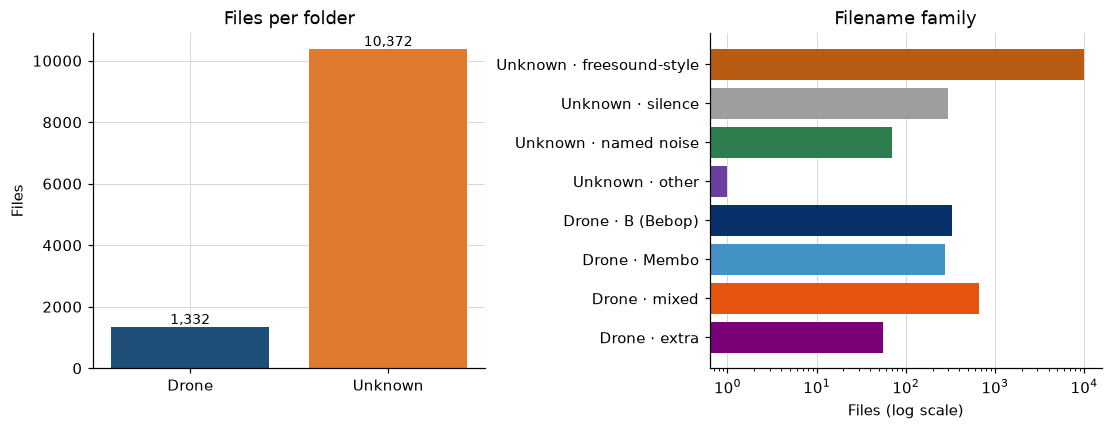

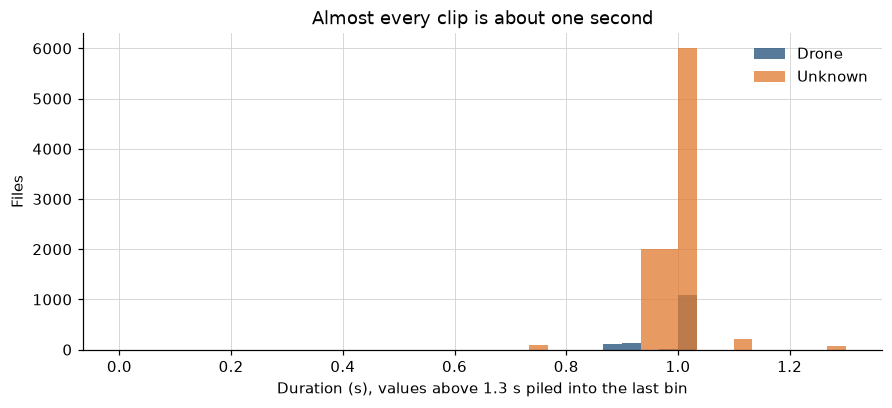

shorter than 0.5 s: 2    longer than 1.3 s: 67
             min  median    max
label                          
unknown    0.002   1.022  5.120
yes_drone  0.650   1.024  1.024
drone parent recordings: 257
slices per parent: min 1 median 5 max 56
parents with more than one slice: 99.6%


In [2]:
rows = []
problems = []
for label in LABEL_ORDER:
    folder = AUDIO_ROOT / label
    if not folder.is_dir():
        problems.append(f"missing folder {folder}")
        continue
    for path in sorted(folder.iterdir()):
        if not path.is_file():
            continue
        try:
            with wave.open(str(path), "rb") as handle:
                channels = handle.getnchannels()
                width = handle.getsampwidth()
                rate = handle.getframerate()
                frames = handle.getnframes()
                comp = handle.getcomptype()
        except wave.Error as exc:
            problems.append(f"{path.name}: {exc}")
            continue
        rows.append({
            "label": label,
            "family": family_of(label, path.name),
            "parent": parent_of(path.name),
            "name": path.name,
            "path": path,
            "channels": channels,
            "width": width,
            "rate": rate,
            "frames": frames,
            "compressed": comp != "NONE",
            "duration_s": frames / rate if rate else np.nan,
            "bytes": path.stat().st_size,
        })

meta = pd.DataFrame(rows)
if problems:
    print("PROBLEMS")
    for item in problems[:20]:
        print(" -", item)
else:
    print(f"{len(meta):,} files, no unreadable wavs")

print("channels", sorted(meta.channels.unique().tolist()))
print("bytes per sample", sorted(meta.width.unique().tolist()))
print("sample rate", sorted(meta.rate.unique().tolist()))
print("any compressed", bool(meta.compressed.any()))
print(f"on disk {meta.bytes.sum() / 1e6:.1f} MB")

counts = meta.groupby("label").size().reindex(LABEL_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
axes[0].bar(
    [LABEL_NAME[k] for k in LABEL_ORDER],
    counts.to_numpy(),
    color=[LABEL_COLOR[k] for k in LABEL_ORDER],
)
axes[0].set_ylabel("Files")
axes[0].set_title("Files per folder")
for x, value in enumerate(counts.to_numpy()):
    axes[0].text(x, value, f"{value:,}", ha="center", va="bottom", fontsize=9)

family_counts = meta.groupby(["label", "family"]).size().reset_index(name="n")
family_counts["family"] = pd.Categorical(family_counts["family"], FAMILY_ORDER, ordered=True)
family_counts = family_counts.sort_values(["label", "family"])
y = np.arange(len(family_counts))
axes[1].barh(
    y,
    family_counts["n"],
    color=[FAMILY_COLOR[f] for f in family_counts["family"]],
)
axes[1].set_yticks(y, [f"{LABEL_NAME[r.label]} · {r.family}" for r in family_counts.itertuples()])
axes[1].invert_yaxis()
axes[1].set_xscale("log")
axes[1].set_xlabel("Files (log scale)")
axes[1].set_title("Filename family")
axes[1].grid(axis="y", visible=False)
show(fig)

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
bins = np.linspace(0, 1.3, 40)
for label in LABEL_ORDER:
    part = meta.loc[meta.label == label, "duration_s"]
    ax.hist(part.clip(upper=1.3), bins=bins, alpha=0.75, label=LABEL_NAME[label], color=LABEL_COLOR[label])
ax.set_xlabel("Duration (s), values above 1.3 s piled into the last bin")
ax.set_ylabel("Files")
ax.set_title("Almost every clip is about one second")
ax.legend()
show(fig)
long = int((meta.duration_s > 1.3).sum())
short = int((meta.duration_s < 0.5).sum())
print(f"shorter than 0.5 s: {short:,}    longer than 1.3 s: {long:,}")
print(meta.groupby("label").duration_s.agg(["min", "median", "max"]).round(3))

drone = meta[meta.label == "yes_drone"]
slices = drone.groupby("parent").size()
print(f"drone parent recordings: {len(slices):,}")
print(f"slices per parent: min {slices.min()} median {slices.median():.0f} max {slices.max()}")
print(f"parents with more than one slice: {(slices > 1).mean():.1%}")


## 3. Level and spectrum

Samples are read as 16-bit mono and scaled to ±1. RMS and peak use the whole file. The spectrum uses the first 1.024 s (16,384 samples), with a Hann window. Clips quieter than −80 dB RMS, or shorter than half a second, are left out of the average spectrum so digital silence does not flatten it. Band shares are fractions of that window's power.


read 0 / 11,704


read 3,000 / 11,704


read 6,000 / 11,704


read 9,000 / 11,704


finished 11,704 files; 10,555 entered the mean spectrum


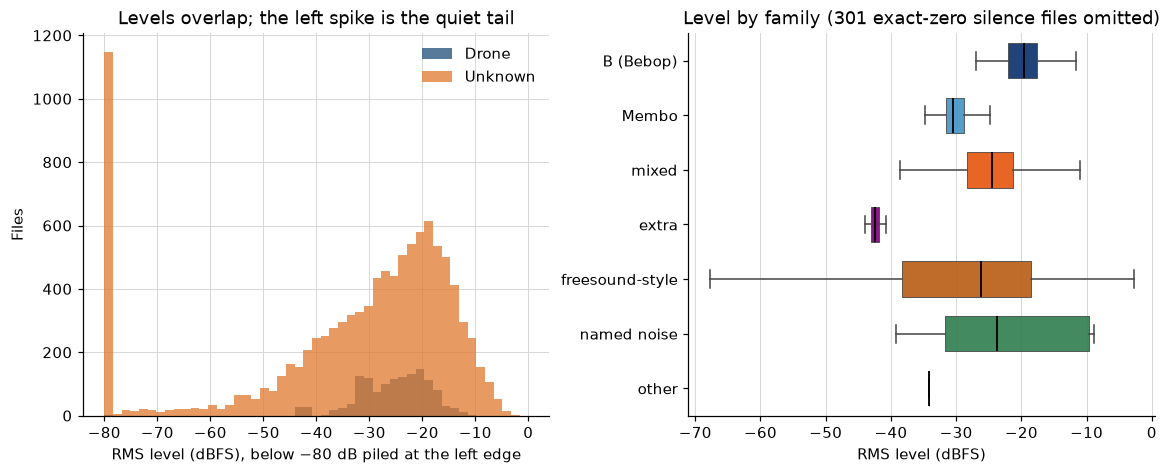

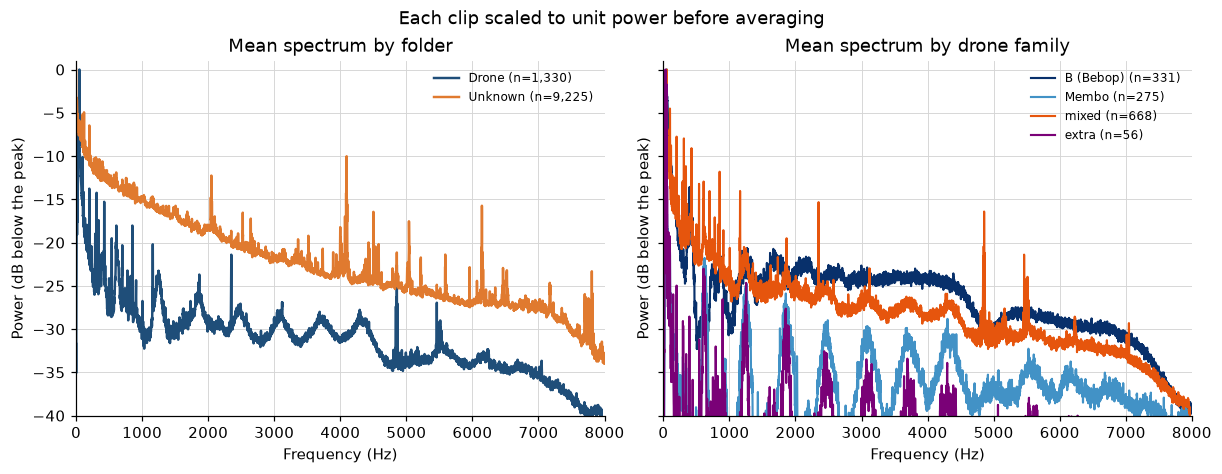

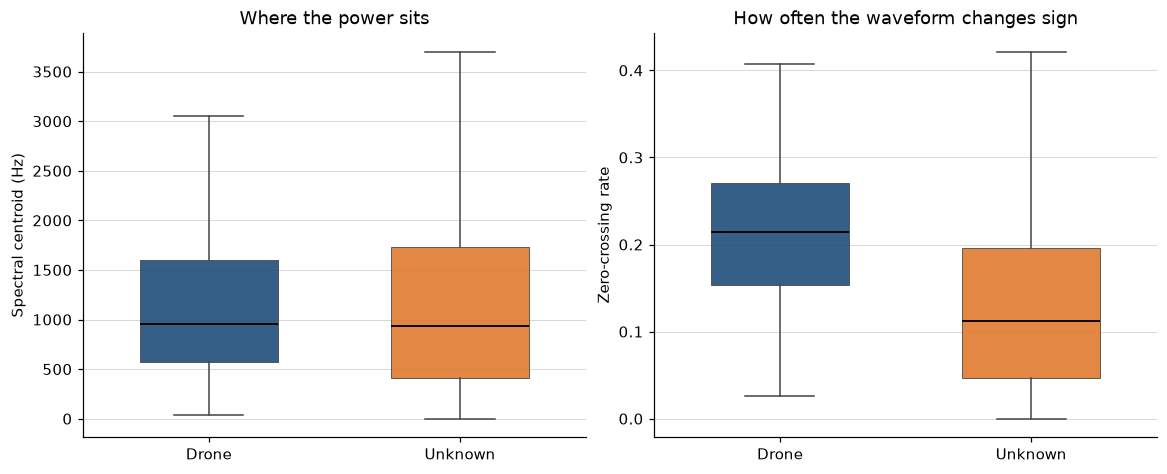

In [3]:
def read_audio(path):
    with wave.open(str(path), "rb") as handle:
        frames = handle.getnframes()
        raw = handle.readframes(frames)
    if frames == 0 or len(raw) < 2:
        return np.zeros(0, dtype=np.float32)
    samples = np.frombuffer(raw, dtype="<i2").astype(np.float32)
    samples *= (1.0 / 32768.0)
    return samples


def window_spectrum(samples):
    clip = samples[:N_FFT]
    if clip.size < N_FFT:
        clip = np.pad(clip, (0, N_FFT - clip.size))
    spectrum = np.fft.rfft(clip * np.hanning(N_FFT))
    return np.abs(spectrum) ** 2


FREQS = np.fft.rfftfreq(N_FFT, d=1 / SR_EXPECTED)
LOW = (FREQS >= LOW_HZ[0]) & (FREQS < LOW_HZ[1])
MID = (FREQS >= MID_HZ[0]) & (FREQS < MID_HZ[1])
HIGH = (FREQS >= HIGH_HZ[0]) & (FREQS < HIGH_HZ[1])

rms_db = np.empty(len(meta), dtype=np.float64)
peak = np.empty(len(meta), dtype=np.float64)
zcr = np.empty(len(meta), dtype=np.float64)
centroid = np.full(len(meta), np.nan)
low_share = np.full(len(meta), np.nan)
mid_share = np.full(len(meta), np.nan)
high_share = np.full(len(meta), np.nan)
used_in_mean = np.zeros(len(meta), dtype=bool)
spec_acc = {label: np.zeros(FREQS.size, dtype=np.float64) for label in LABEL_ORDER}
spec_n = {label: 0 for label in LABEL_ORDER}
family_acc = {name: np.zeros(FREQS.size, dtype=np.float64) for name in FAMILY_ORDER}
family_n = {name: 0 for name in FAMILY_ORDER}

for i, row in enumerate(meta.itertuples(index=False)):
    samples = read_audio(row.path)
    if samples.size == 0:
        rms_db[i] = -120
        peak[i] = 0
        zcr[i] = 0
        continue
    rms = float(np.sqrt(np.mean(samples ** 2)))
    rms_db[i] = 20 * np.log10(max(rms, 1e-12))
    peak[i] = float(np.max(np.abs(samples)))
    zcr[i] = float(np.mean(samples[1:] * samples[:-1] < 0)) if samples.size > 1 else 0.0
    power = window_spectrum(samples)
    total = float(power.sum())
    if total > 0:
        centroid[i] = float(np.sum(FREQS * power) / total)
        low_share[i] = float(power[LOW].sum() / total)
        mid_share[i] = float(power[MID].sum() / total)
        high_share[i] = float(power[HIGH].sum() / total)
    if rms >= 1e-4 and samples.size >= 8000 and total > 0:
        norm = power / total
        spec_acc[row.label] += norm
        spec_n[row.label] += 1
        family_acc[row.family] += norm
        family_n[row.family] += 1
        used_in_mean[i] = True
    if i % 3000 == 0:
        print(f"read {i:,} / {len(meta):,}")

meta = meta.copy()
meta["rms_db"] = rms_db
meta["peak"] = peak
meta["zcr"] = zcr
meta["centroid_hz"] = centroid
meta["low_share"] = low_share
meta["mid_share"] = mid_share
meta["high_share"] = high_share
meta["in_mean_spectrum"] = used_in_mean
print(f"finished {len(meta):,} files; {int(used_in_mean.sum()):,} entered the mean spectrum")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), layout="constrained")
bins = np.linspace(-80, 0, 50)
for label in LABEL_ORDER:
    axes[0].hist(
        meta.loc[meta.label == label, "rms_db"].clip(-80, 0),
        bins=bins, alpha=0.75, label=LABEL_NAME[label], color=LABEL_COLOR[label],
    )
axes[0].set_xlabel("RMS level (dBFS), below −80 dB piled at the left edge")
axes[0].set_ylabel("Files")
axes[0].set_title("Levels overlap; the left spike is the quiet tail")
axes[0].legend()

order = [f for f in FAMILY_ORDER if f != "silence" and (meta.family == f).any()]
arrays = [meta.loc[meta.family == name, "rms_db"].to_numpy() for name in reversed(order)]
bp = axes[1].boxplot(
    arrays,
    orientation="horizontal",
    tick_labels=list(reversed(order)),
    showfliers=False,
    patch_artist=True,
    widths=0.65,
    medianprops={"color": "black", "linewidth": 1.2},
    whiskerprops={"color": "#444444"},
    capprops={"color": "#444444"},
    boxprops={"linewidth": 0.6, "color": "#444444"},
)
for patch, name in zip(bp["boxes"], reversed(order)):
    patch.set_facecolor(FAMILY_COLOR[name])
    patch.set_alpha(0.9)
axes[1].set_xlabel("RMS level (dBFS)")
axes[1].set_title("Level by family (301 exact-zero silence files omitted)")
axes[1].grid(axis="y", visible=False)
show(fig)

def db_from_acc(acc, n):
    if n == 0:
        return None
    mean = acc / n
    mean = mean / mean.max()
    return 10 * np.log10(np.maximum(mean, 1e-12))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained", sharey=True)
for label in LABEL_ORDER:
    curve = db_from_acc(spec_acc[label], spec_n[label])
    axes[0].plot(FREQS, curve, color=LABEL_COLOR[label], label=f"{LABEL_NAME[label]} (n={spec_n[label]:,})", lw=1.6)
axes[0].set_title("Mean spectrum by folder")
for name in ["B (Bebop)", "Membo", "mixed", "extra"]:
    curve = db_from_acc(family_acc[name], family_n[name])
    if curve is None:
        continue
    axes[1].plot(FREQS, curve, color=FAMILY_COLOR[name], label=f"{name} (n={family_n[name]:,})", lw=1.4)
axes[1].set_title("Mean spectrum by drone family")
for ax in axes:
    ax.set_xlim(0, 8000)
    ax.set_ylim(-40, 1)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Power (dB below the peak)")
    ax.legend(fontsize=8)
fig.suptitle("Each clip scaled to unit power before averaging", fontsize=12)
show(fig)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), layout="constrained")
for ax, column, xlabel, title in (
    (axes[0], "centroid_hz", "Spectral centroid (Hz)", "Where the power sits"),
    (axes[1], "zcr", "Zero-crossing rate", "How often the waveform changes sign"),
):
    arrays = [meta.loc[meta.label == label, column].dropna().to_numpy() for label in LABEL_ORDER]
    bp = ax.boxplot(
        arrays,
        tick_labels=[LABEL_NAME[label] for label in LABEL_ORDER],
        showfliers=False,
        patch_artist=True,
        widths=0.55,
        medianprops={"color": "black", "linewidth": 1.2},
        whiskerprops={"color": "#444444"},
        capprops={"color": "#444444"},
        boxprops={"linewidth": 0.6, "color": "#444444"},
    )
    for patch, label in zip(bp["boxes"], LABEL_ORDER):
        patch.set_facecolor(LABEL_COLOR[label])
        patch.set_alpha(0.9)
    ax.set_ylabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
show(fig)


## 4. A few clips, heard as pictures

Each panel is one file whose RMS is closest to the median of its family, among clips that entered the mean spectrum. The spectrogram is a 512-point Hann STFT (32 ms window, 8 ms hop), drawn in dB relative to that clip's own peak.


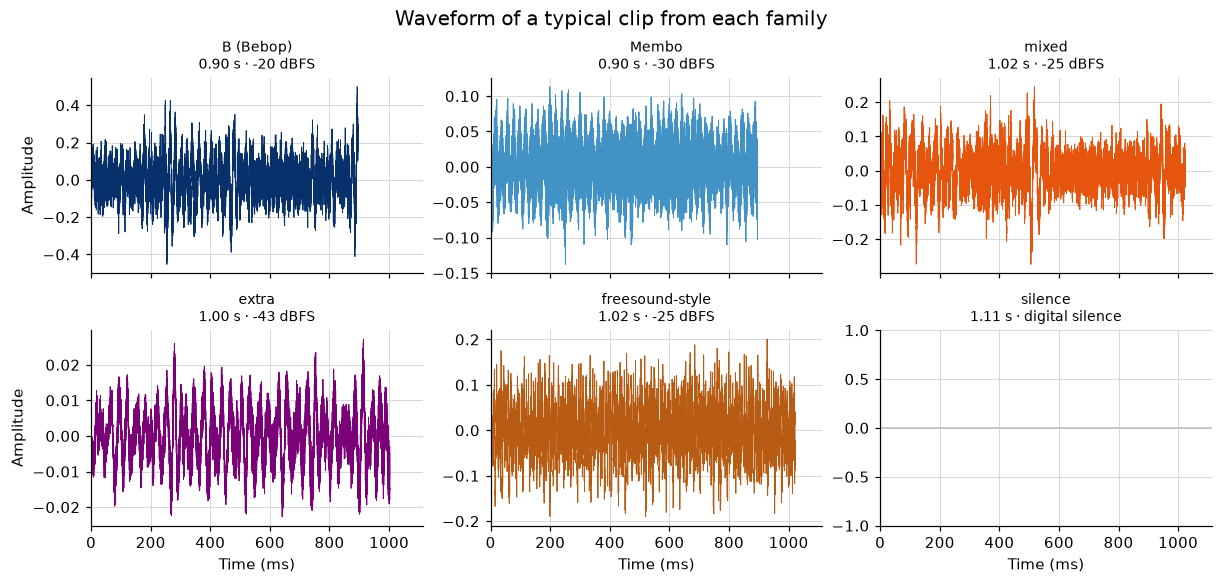

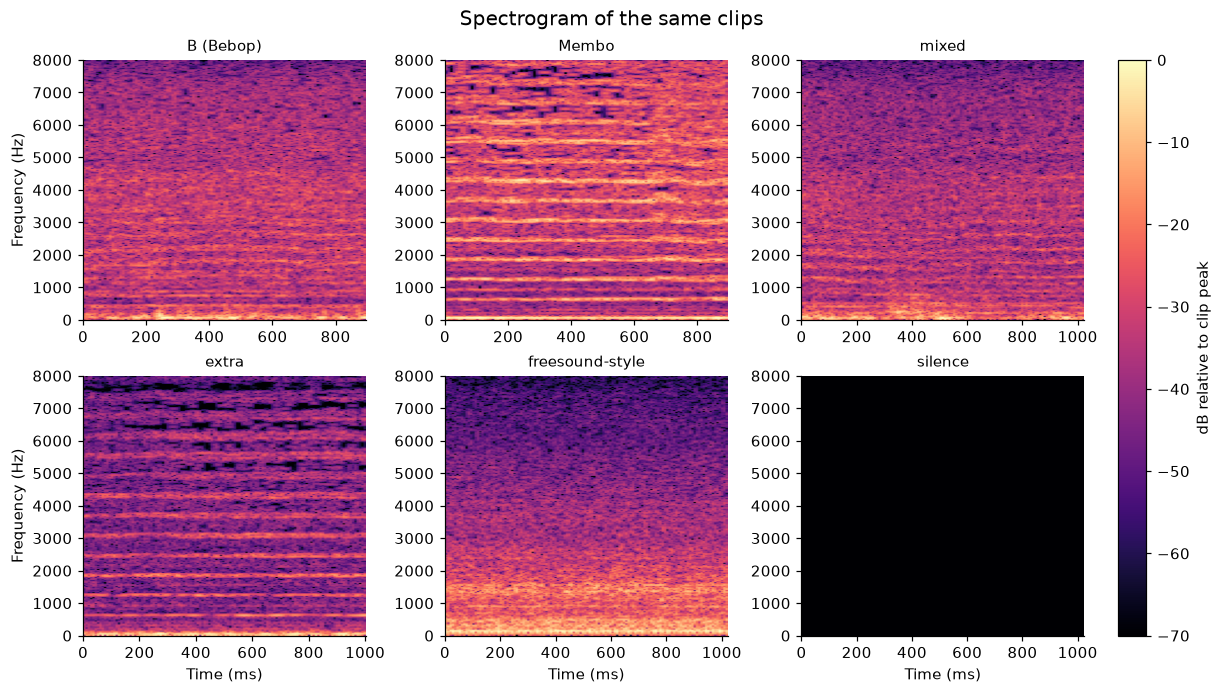

In [4]:
def pick(family):
    pool = meta[(meta.family == family) & meta.in_mean_spectrum]
    if pool.empty:
        pool = meta[meta.family == family]
    median = pool.rms_db.median()
    return pool.iloc[(pool.rms_db - median).abs().argmin()]


show_families = ["B (Bebop)", "Membo", "mixed", "extra", "freesound-style", "silence"]
chosen = [pick(name) for name in show_families]


def spectrogram_db(samples, n_fft=512, hop=128):
    if samples.size < n_fft:
        samples = np.pad(samples, (0, n_fft - samples.size))
    window = np.hanning(n_fft)
    frames = 1 + (samples.size - n_fft) // hop
    grid = np.empty((n_fft // 2 + 1, frames), dtype=np.float64)
    for i in range(frames):
        start = i * hop
        grid[:, i] = np.abs(np.fft.rfft(samples[start:start + n_fft] * window))
    peak = float(grid.max())
    if peak <= 0:
        return np.full_like(grid, -70.0)
    return 20 * np.log10(grid / peak + 1e-12)


fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), layout="constrained", sharex=True)
for ax, row in zip(axes.ravel(), chosen):
    samples = read_audio(row.path)
    t_ms = np.arange(samples.size) / SR_EXPECTED * 1e3
    ax.plot(t_ms, samples, color=FAMILY_COLOR[row.family], lw=0.6)
    level = "digital silence" if row.rms_db < -120 else f"{row.rms_db:.0f} dBFS"
    ax.set_title(f"{row.family}\n{row.duration_s:.2f} s · {level}", fontsize=9)
    ax.set_xlim(0, max(t_ms[-1] if t_ms.size else 0, 1))
    if row.rms_db < -120:
        ax.set_ylim(-1, 1)
for ax in axes[-1]:
    ax.set_xlabel("Time (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("Amplitude")
fig.suptitle("Waveform of a typical clip from each family", fontsize=13)
show(fig)

fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), layout="constrained")
image = None
for ax, row in zip(axes.ravel(), chosen):
    samples = read_audio(row.path)
    shown = samples[:N_FFT]
    db = spectrogram_db(shown)
    duration_ms = shown.size / SR_EXPECTED * 1e3
    image = ax.imshow(
        db, origin="lower", aspect="auto",
        extent=(0, duration_ms, 0, SR_EXPECTED / 2),
        vmin=-70, vmax=0, cmap="magma",
    )
    ax.set_ylim(0, 8000)
    ax.set_title(row.family, fontsize=10)
    ax.grid(False)
for ax in axes[-1]:
    ax.set_xlabel("Time (ms)")
for ax in axes[:, 0]:
    ax.set_ylabel("Frequency (Hz)")
fig.colorbar(image, ax=axes.ravel().tolist(), fraction=0.03, pad=0.02, label="dB relative to clip peak")
fig.suptitle("Spectrogram of the same clips", fontsize=13)
show(fig)


## 5. Summary


In [5]:
def median(frame, column):
    return float(frame[column].median())


drone = meta[meta.label == "yes_drone"]
unknown = meta[meta.label == "unknown"]
silence = meta[meta.family == "silence"]
audible_unknown = unknown[unknown.family != "silence"]
slices = drone.groupby("parent").size()
long_unknown = int((unknown.duration_s > 1.3).sum())
short_unknown = int((unknown.duration_s < 0.5).sum())
n_digital_silence = int((silence.rms_db < -120).sum())
quiet_unknown = int((unknown.rms_db < -60).sum())

rows = []
for label in LABEL_ORDER:
    part = meta[meta.label == label]
    rows.append({
        "Folder": LABEL_NAME[label],
        "Files": int(len(part)),
        "Hours": part.duration_s.sum() / 3600,
        "Median duration (s)": part.duration_s.median(),
        "Median RMS (dBFS)": part.rms_db.median(),
        "Median centroid (Hz)": part.centroid_hz.median(),
        "Median power below 300 Hz": part.low_share.median(),
        "Median power 0.3–2 kHz": part.mid_share.median(),
        "Median power 2–8 kHz": part.high_share.median(),
    })
summary = pd.DataFrame(rows)
display(summary.style.format({
    "Files": "{:,}",
    "Hours": "{:.2f}",
    "Median duration (s)": "{:.3f}",
    "Median RMS (dBFS)": "{:.1f}",
    "Median centroid (Hz)": "{:.0f}",
    "Median power below 300 Hz": "{:.2f}",
    "Median power 0.3–2 kHz": "{:.2f}",
    "Median power 2–8 kHz": "{:.2f}",
}).hide(axis="index"))

text = f'''
The folder holds **{len(meta):,}** mono 16-bit wavs at **{int(meta.rate.mode().iloc[0]):,} Hz**, **{meta.bytes.sum() / 1e6:.0f} MB** on disk. **{len(drone):,}** are drone and **{len(unknown):,}** are unknown, so unknown is **{len(unknown) / len(drone):.1f}×** larger. A model that always says "unknown" is already right about **{len(unknown) / len(meta):.0%}** of files.

**The drone files are slices, not independent flights.** {len(slices):,} parent names cover the {len(drone):,} drone files. The median parent has **{slices.median():.0f}** slices and {int((slices > 1).sum())} of {len(slices)} parents have more than one. A random split of files puts neighboring seconds of the same recording on both sides of the split.

**Unknown is not one kind of sound.** {int((unknown.family == "freesound-style").sum()):,} files use Freesound-style names (`fold-id-take-code.wav`) spread across {unknown.loc[unknown.family == "freesound-style", "name"].str.extract(r"-(\d+)\.wav$")[0].nunique()} trailing codes. Another **{len(silence):,}** files are named `silence`, and **{int((unknown.family == "named noise").sum()):,}** are named noise (dishes, exercise bike, tap, pink noise, white noise). All **{n_digital_silence}** silence files are digital zeros. The other unknown files have median RMS **{median(audible_unknown, "rms_db"):.0f} dBFS**, next to the drone median of **{median(drone, "rms_db"):.0f} dBFS**. {short_unknown:,} unknown files are shorter than 0.5 s and {long_unknown:,} are longer than 1.3 s; drone duration stays between {drone.duration_s.min():.2f} s and {drone.duration_s.max():.2f} s.

**Median loudness barely separates the folders.** Median RMS is {median(drone, "rms_db"):.1f} dBFS for drone and {median(unknown, "rms_db"):.1f} dBFS for unknown, and the histograms overlap. Unknown also has a quiet tail: {quiet_unknown:,} unknown files are below −60 dBFS, including the digital silence. **Spectrum shape is the clearer difference.** Median share of power below 300 Hz is {median(drone, "low_share"):.2f} for drone and {median(unknown, "low_share"):.2f} for unknown. The drone mean spectrum is a low hum plus harmonics; the unknown mean spectrum is smoother. Bebop and mixed stay broad, while Membo and extra are more tonal. Median centroids are close ({median(drone, "centroid_hz"):.0f} Hz versus {median(unknown, "centroid_hz"):.0f} Hz), so that one number hides the harmonic structure. A loudness threshold will not separate these folders.
'''
display(Markdown(textwrap.dedent(text).strip()))


Folder,Files,Hours,Median duration (s),Median RMS (dBFS),Median centroid (Hz),Median power below 300 Hz,Median power 0.3–2 kHz,Median power 2–8 kHz
Drone,"1,332",0.37,1.024,-24.6,958,0.60,0.16,0.17
Unknown,"10,372",2.96,1.022,-26.8,938,0.22,0.41,0.08


The folder holds **11,704** mono 16-bit wavs at **16,000 Hz**, **384 MB** on disk. **1,332** are drone and **10,372** are unknown, so unknown is **7.8×** larger. A model that always says "unknown" is already right about **89%** of files.

**The drone files are slices, not independent flights.** 257 parent names cover the 1,332 drone files. The median parent has **5** slices and 256 of 257 parents have more than one. A random split of files puts neighboring seconds of the same recording on both sides of the split.

**Unknown is not one kind of sound.** 10,000 files use Freesound-style names (`fold-id-take-code.wav`) spread across 250 trailing codes. Another **301** files are named `silence`, and **70** are named noise (dishes, exercise bike, tap, pink noise, white noise). All **301** silence files are digital zeros. The other unknown files have median RMS **-26 dBFS**, next to the drone median of **-25 dBFS**. 2 unknown files are shorter than 0.5 s and 67 are longer than 1.3 s; drone duration stays between 0.65 s and 1.02 s.

**Median loudness barely separates the folders.** Median RMS is -24.6 dBFS for drone and -26.8 dBFS for unknown, and the histograms overlap. Unknown also has a quiet tail: 1,349 unknown files are below −60 dBFS, including the digital silence. **Spectrum shape is the clearer difference.** Median share of power below 300 Hz is 0.60 for drone and 0.22 for unknown. The drone mean spectrum is a low hum plus harmonics; the unknown mean spectrum is smoother. Bebop and mixed stay broad, while Membo and extra are more tonal. Median centroids are close (958 Hz versus 938 Hz), so that one number hides the harmonic structure. A loudness threshold will not separate these folders.